In [ ]:
# Mount Google Drive after a fresh session
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Project directory on Google Drive
PROJECT_PATH = '/content/drive/MyDrive/Insight_Hunters_Project'

# Separate folders for the standardized run so the original results stay untouched
CHECKPOINT_PATH = os.path.join(PROJECT_PATH, '03_Model_Checkpoints', 'DenseNet121_Standardized')
RESULTS_PATH = os.path.join(PROJECT_PATH, '04_Results', 'DenseNet121_Standardized')

os.makedirs(CHECKPOINT_PATH, exist_ok=True)
os.makedirs(RESULTS_PATH, exist_ok=True)

print("Checkpoint folder ready:", CHECKPOINT_PATH)
print("Results folder ready:", RESULTS_PATH)

Checkpoint folder ready: /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized
Results folder ready: /content/drive/MyDrive/Insight_Hunters_Project/04_Results/DenseNet121_Standardized


In [ ]:
# Import libraries needed for data loading, model building and plotting
import os
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Fix the random seed so results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
GPU available: True


In [ ]:
# Paths to the existing train and validation splits
SPLITS_PATH = os.path.join(PROJECT_PATH, '02_Data_Splits')
TRAIN_DIR = os.path.join(SPLITS_PATH, 'train')
VAL_DIR = os.path.join(SPLITS_PATH, 'val')

# Expected class folders in each split
EXPECTED_CLASSES = ['tb_negative', 'tb_positive']

print("=" * 65)
print("DENSENET121 - DATASET PATH VERIFICATION")
print("=" * 65)

for name, directory in [('Training', TRAIN_DIR), ('Validation', VAL_DIR)]:
    if not os.path.exists(directory):
        raise FileNotFoundError(f"{name} directory not found: {directory}")

    class_folders = sorted(
        folder for folder in os.listdir(directory)
        if os.path.isdir(os.path.join(directory, folder))
    )

    if class_folders != EXPECTED_CLASSES:
        raise ValueError(
            f"{name} class folders incorrect. "
            f"Expected {EXPECTED_CLASSES}, found {class_folders}"
        )

    print(f"✓ {name} directory")
    print(f"  Classes: {class_folders}")

print()
print("TEST SET: NOT LOADED - LOCKED FOR FINAL EVALUATION")
print("=" * 65)

DENSENET121 - DATASET PATH VERIFICATION
✓ Training directory
  Classes: ['tb_negative', 'tb_positive']
✓ Validation directory
  Classes: ['tb_negative', 'tb_positive']

TEST SET: NOT LOADED - LOCKED FOR FINAL EVALUATION


In [ ]:
# Image size and batch size match the shared model protocol
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load training data from the folder structure
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels='inferred',
    label_mode='binary',
    class_names=EXPECTED_CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Load validation data from the folder structure
# Validation is not shuffled so evaluation is consistent between runs
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels='inferred',
    label_mode='binary',
    class_names=EXPECTED_CLASSES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Confirm the class mapping matches the protocol
# This check must happen before prefetch because prefetch changes the object type
print("Training class names:", train_ds.class_names)
print("Validation class names:", val_ds.class_names)

if train_ds.class_names != EXPECTED_CLASSES:
    raise ValueError(f"Training class mapping incorrect: {train_ds.class_names}")

if val_ds.class_names != EXPECTED_CLASSES:
    raise ValueError(f"Validation class mapping incorrect: {val_ds.class_names}")

# Prefetch for faster training
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

print("Datasets loaded and prefetched.")

Found 560 files belonging to 2 classes.
Found 120 files belonging to 2 classes.
Training class names: ['tb_negative', 'tb_positive']
Validation class names: ['tb_negative', 'tb_positive']
Datasets loaded and prefetched.


In [ ]:
data_augmentation = keras.Sequential(
    [
        # Rotate images by up to 5 degrees
        layers.RandomRotation(factor=5 / 360, seed=SEED),

        # Shift images by up to 5 percent in either direction
        layers.RandomTranslation(height_factor=0.05, width_factor=0.05, seed=SEED),

        # Zoom in or out by up to 10 percent
        layers.RandomZoom(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10), seed=SEED),

        # Adjust contrast by up to 10 percent
        layers.RandomContrast(factor=0.10, seed=SEED),
    ],
    name='standardized_data_augmentation'
)

In [ ]:
# Load DenseNet121 with ImageNet pretrained weights
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the entire backbone for Stage 1
base_model.trainable = False

# Build the model
inputs = keras.Input(shape=(224, 224, 3), name='input_image')

# Training-only augmentation
x = data_augmentation(inputs)

# DenseNet121 specific preprocessing
x = preprocess_input(x)

# Frozen DenseNet121 feature extractor
x = base_model(x, training=False)

# Custom binary classification head
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.Dropout(0.5, seed=SEED, name='dropout')(x)

# Intermediate dense layer to give the head more capacity to learn
x = layers.Dense(128, activation='relu', name='dense_features')(x)

# Output layer for binary classification
outputs = layers.Dense(1, activation='sigmoid', name='tb_prediction')(x)

# Full model
model = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name='InsightHunters_DenseNet121_TB'
)

# Compile for Stage 1
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy')]
)

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "InsightHunters_DenseNet121_TB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ standardized_data_augmentation  │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tb_prediction (Dense)           │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,168,833 (27.35 MB)

 Trainable params: 131,329 (513.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
# Stage 1 checkpoint path for the standardized run
stage1_checkpoint = os.path.join(CHECKPOINT_PATH, 'stage1_best.keras')

# Callbacks for Stage 1
# EarlyStopping stops training when validation loss stops improving
# ModelCheckpoint saves the best model whenever validation loss improves
# No learning rate reduction during Stage 1 so the head can learn steadily
callbacks_stage1 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(stage1_checkpoint, monitor='val_loss', save_best_only=True, verbose=1)
]

# Confirm backbone is still frozen before training
if base_model.trainable:
    raise RuntimeError('DenseNet121 backbone should be frozen for Stage 1.')

print("=" * 65)
print("DENSENET121 - STAGE 1 CONFIGURATION")
print("=" * 65)
print("Training images:           560")
print("Validation images:         120")
print("Input:                     224 x 224 x 3")
print("Batch size:                32")
print()
print("Backbone:                  DenseNet121 ImageNet")
print("Backbone frozen:           YES")
print()
print("Optimizer:                 Adam")
print("Learning rate:             1e-4")
print("Loss:                      Binary Cross-Entropy")
print()
print("Maximum epochs:            25")
print("Early stopping patience:   5")
print("Checkpoint monitor:        val_loss")
print()
print("Stage 1 checkpoint:")
print(stage1_checkpoint)
print()
print("Test set:                  LOCKED / NOT LOADED")
print("=" * 65)

DENSENET121 - STAGE 1 CONFIGURATION
Training images:           560
Validation images:         120
Input:                     224 x 224 x 3
Batch size:                32

Backbone:                  DenseNet121 ImageNet
Backbone frozen:           YES

Optimizer:                 Adam
Learning rate:             1e-4
Loss:                      Binary Cross-Entropy

Maximum epochs:            25
Early stopping patience:   5
Checkpoint monitor:        val_loss

Stage 1 checkpoint:
/content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized/stage1_best.keras

Test set:                  LOCKED / NOT LOADED


In [ ]:
print("=" * 65)
print("DENSENET121 - STARTING STAGE 1 TRAINING")
print("=" * 65)
print("Backbone:        FROZEN")
print("Maximum epochs:  25")
print("Monitor:         val_loss")
print("Test set:        NOT USED")
print("=" * 65)

# Record the training start time
start_time = time.time()

# Train the model
history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks_stage1,
    verbose=1
)

# Record the training duration
stage1_duration = time.time() - start_time

# Extract the best Stage 1 results
stage1_epochs_completed = len(history_stage1.history['loss'])
stage1_best_epoch = int(np.argmin(history_stage1.history['val_loss']) + 1)
stage1_best_val_loss = float(np.min(history_stage1.history['val_loss']))
stage1_best_val_accuracy = float(
    history_stage1.history['val_accuracy'][stage1_best_epoch - 1]
)

print()
print("=" * 65)
print("DENSENET121 - STAGE 1 TRAINING COMPLETE")
print("=" * 65)
print(f"Epochs completed:       {stage1_epochs_completed}")
print(f"Best epoch by val_loss: {stage1_best_epoch}")
print(f"Best validation loss:   {stage1_best_val_loss:.4f}")
print(f"Validation accuracy:    {stage1_best_val_accuracy:.4f}")
print(f"Training duration:      {stage1_duration / 60:.2f} minutes")
print()
print("Best Stage 1 checkpoint:")
print(stage1_checkpoint)
print()
print("Test set used:          NO")
print("=" * 65)

DENSENET121 - STARTING STAGE 1 TRAINING
Backbone:        FROZEN
Maximum epochs:  25
Monitor:         val_loss
Test set:        NOT USED
Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.4944 - loss: 0.8748
Epoch 1: val_loss improved from None to 0.67486, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized/stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized/stage1_best.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 190s 11s/step - accuracy: 0.5196 - loss: 0.8351 - val_accuracy: 0.5667 - val_loss: 0.6749
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.5257 - loss: 0.7836
Epoch 2: val_loss improved from 0.67486 to 0.64771, saving model to /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized/stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Insight_Hunters_Projec

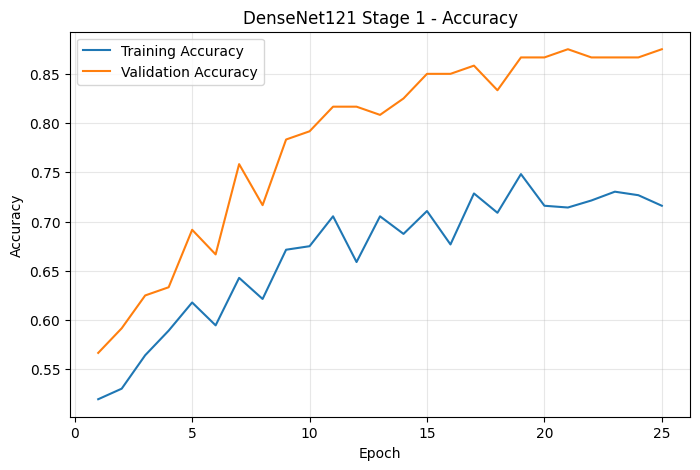

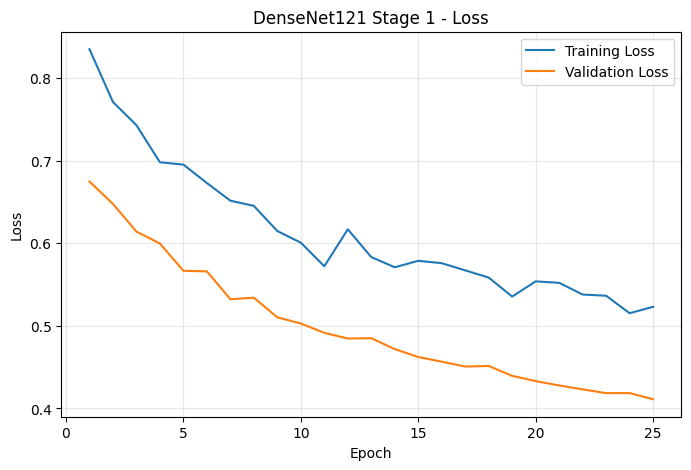

Best Stage 1 validation accuracy: 0.8750


In [ ]:
# Extract the Stage 1 history for plotting
stage1_epochs = range(1, len(history_stage1.history['loss']) + 1)

# Plot Stage 1 accuracy
plt.figure(figsize=(8, 5))
plt.plot(stage1_epochs, history_stage1.history['accuracy'], label='Training Accuracy')
plt.plot(stage1_epochs, history_stage1.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('DenseNet121 Stage 1 - Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(RESULTS_PATH, 'stage1_accuracy.png'), dpi=150)
plt.show()

# Plot Stage 1 loss
plt.figure(figsize=(8, 5))
plt.plot(stage1_epochs, history_stage1.history['loss'], label='Training Loss')
plt.plot(stage1_epochs, history_stage1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DenseNet121 Stage 1 - Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(RESULTS_PATH, 'stage1_loss.png'), dpi=150)
plt.show()

# Show the best Stage 1 validation accuracy
best_val_acc_s1 = max(history_stage1.history['val_accuracy'])
print(f"Best Stage 1 validation accuracy: {best_val_acc_s1:.4f}")

In [ ]:
# Load the best Stage 1 weights
model.load_weights(stage1_checkpoint)

# Unfreeze the backbone
base_model.trainable = True

# Unfreeze only the conv5 block
# Batch Norm layers stay frozen to keep DenseNet stable during fine-tuning
for layer in base_model.layers:
    if 'conv5' in layer.name:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True
    else:
        layer.trainable = False

# Count how many layers are now trainable
trainable_backbone_layers = [layer.name for layer in base_model.layers if layer.trainable]
print(f"Trainable backbone layers: {len(trainable_backbone_layers)}")
for name in trainable_backbone_layers:
    print(f"  {name}")

# Recompile with a smaller learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy')]
)

stage2_checkpoint = os.path.join(CHECKPOINT_PATH, 'stage2_best.keras')

# Stage 2 callbacks
callbacks_stage2 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint(stage2_checkpoint, monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=1e-7, verbose=1)
]

print()
print("=" * 65)
print("DENSENET121 - STAGE 2 CONFIGURATION")
print("=" * 65)
print("Stage 1 checkpoint:       LOADED")
print("Backbone:                 PARTIALLY UNFROZEN")
print("Frozen section:           Everything except conv5")
print("Trainable section:        conv5 block (Batch Norm frozen)")
print("Fine-tuning LR:           1e-5")
print("Maximum Stage 2 epochs:   15")
print("Test set:                 STILL LOCKED")
print("=" * 65)

# Record the training start time
start_time = time.time()

# Stage 2 fine-tuning, max 15 epochs to match the reference
history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_stage2,
    verbose=1
)

# Record the training duration
stage2_duration = time.time() - start_time

# Extract the best Stage 2 results
stage2_epochs_completed = len(history_stage2.history['loss'])
stage2_best_epoch = int(np.argmin(history_stage2.history['val_loss']) + 1)
stage2_best_val_loss = float(np.min(history_stage2.history['val_loss']))
stage2_best_val_accuracy = float(history_stage2.history['val_accuracy'][stage2_best_epoch - 1])

print()
print("=" * 65)
print("DENSENET121 - STAGE 2 FINE-TUNING COMPLETE")
print("=" * 65)
print(f"Epochs completed:       {stage2_epochs_completed}")
print(f"Best epoch by val_loss: {stage2_best_epoch}")
print(f"Best validation loss:   {stage2_best_val_loss:.4f}")
print(f"Validation accuracy:    {stage2_best_val_accuracy:.4f}")
print(f"Training duration:      {stage2_duration / 60:.2f} minutes")
print()
print("Best Stage 2 checkpoint:")
print(stage2_checkpoint)
print()
print("Test set used:          NO")
print("=" * 65)

Trainable backbone layers: 80
  conv5_block1_0_relu
  conv5_block1_1_conv
  conv5_block1_1_relu
  conv5_block1_2_conv
  conv5_block1_concat
  conv5_block2_0_relu
  conv5_block2_1_conv
  conv5_block2_1_relu
  conv5_block2_2_conv
  conv5_block2_concat
  conv5_block3_0_relu
  conv5_block3_1_conv
  conv5_block3_1_relu
  conv5_block3_2_conv
  conv5_block3_concat
  conv5_block4_0_relu
  conv5_block4_1_conv
  conv5_block4_1_relu
  conv5_block4_2_conv
  conv5_block4_concat
  conv5_block5_0_relu
  conv5_block5_1_conv
  conv5_block5_1_relu
  conv5_block5_2_conv
  conv5_block5_concat
  conv5_block6_0_relu
  conv5_block6_1_conv
  conv5_block6_1_relu
  conv5_block6_2_conv
  conv5_block6_concat
  conv5_block7_0_relu
  conv5_block7_1_conv
  conv5_block7_1_relu
  conv5_block7_2_conv
  conv5_block7_concat
  conv5_block8_0_relu
  conv5_block8_1_conv
  conv5_block8_1_relu
  conv5_block8_2_conv
  conv5_block8_concat
  conv5_block9_0_relu
  conv5_block9_1_conv
  conv5_block9_1_relu
  conv5_block9_2_conv
  

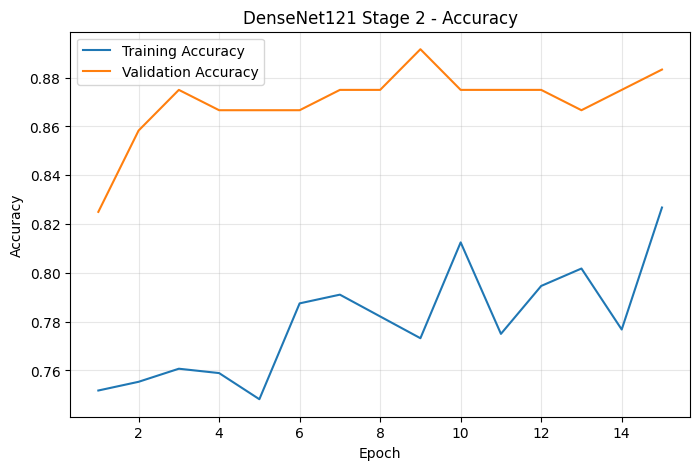

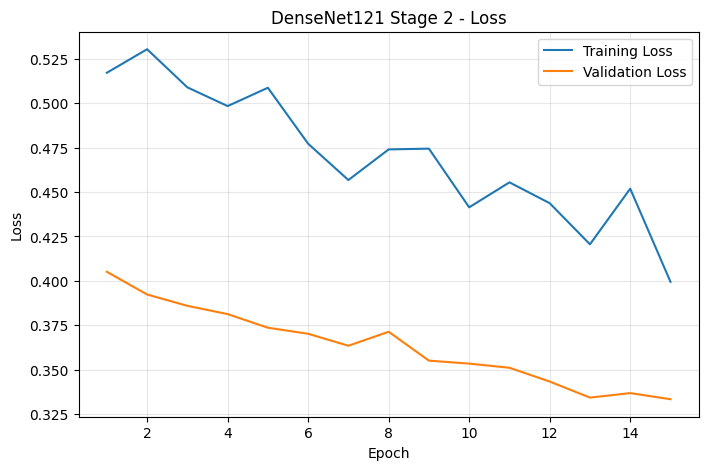

All outputs saved.
{
  "model": "DenseNet121",
  "image_size": [
    224,
    224,
    3
  ],
  "batch_size": 32,
  "seed": 42,
  "class_mapping": {
    "0": "tb_negative",
    "1": "tb_positive"
  },
  "stage1_epochs_run": 25,
  "stage2_epochs_run": 15,
  "stage1_learning_rate": 0.0001,
  "stage2_learning_rate": 1e-05,
  "optimizer": "Adam",
  "loss": "binary_crossentropy",
  "stage1_duration_minutes": 37.44,
  "stage2_duration_minutes": 20.41,
  "total_parameters": 7168833,
  "preprocessing": "DenseNet121 preprocess_input",
  "augmentation": "rotation 5 degrees, translation 5%, zoom 10%, contrast 10%, no flips",
  "fine_tuned_layers": "conv5 block only (Batch Norm frozen)",
  "best_stage1_val_accuracy": 0.875,
  "best_stage2_val_accuracy": 0.8916666507720947,
  "best_stage2_val_loss": 0.3333451449871063
}


In [ ]:
# Extract the Stage 2 history for plotting
stage2_epochs = range(1, len(history_stage2.history['loss']) + 1)

# Plot Stage 2 accuracy
plt.figure(figsize=(8, 5))
plt.plot(stage2_epochs, history_stage2.history['accuracy'], label='Training Accuracy')
plt.plot(stage2_epochs, history_stage2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('DenseNet121 Stage 2 - Accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(RESULTS_PATH, 'stage2_accuracy.png'), dpi=150)
plt.show()

# Plot Stage 2 loss
plt.figure(figsize=(8, 5))
plt.plot(stage2_epochs, history_stage2.history['loss'], label='Training Loss')
plt.plot(stage2_epochs, history_stage2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('DenseNet121 Stage 2 - Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(RESULTS_PATH, 'stage2_loss.png'), dpi=150)
plt.show()

# Save both training histories as CSV files
pd.DataFrame(history_stage1.history).to_csv(
    os.path.join(RESULTS_PATH, 'stage1_history.csv'), index=False
)
pd.DataFrame(history_stage2.history).to_csv(
    os.path.join(RESULTS_PATH, 'stage2_history.csv'), index=False
)

# Best Stage 2 validation results
best_val_acc_s2 = max(history_stage2.history['val_accuracy'])
best_val_loss_s2 = min(history_stage2.history['val_loss'])

# Save a config file documenting the standardized settings
config = {
    'model': 'DenseNet121',
    'image_size': [224, 224, 3],
    'batch_size': 32,
    'seed': 42,
    'class_mapping': {'0': 'tb_negative', '1': 'tb_positive'},
    'stage1_epochs_run': stage1_epochs_completed,
    'stage2_epochs_run': stage2_epochs_completed,
    'stage1_learning_rate': 1e-4,
    'stage2_learning_rate': 1e-5,
    'optimizer': 'Adam',
    'loss': 'binary_crossentropy',
    'stage1_duration_minutes': round(stage1_duration / 60, 2),
    'stage2_duration_minutes': round(stage2_duration / 60, 2),
    'total_parameters': model.count_params(),
    'preprocessing': 'DenseNet121 preprocess_input',
    'augmentation': 'rotation 5 degrees, translation 5%, zoom 10%, contrast 10%, no flips',
    'fine_tuned_layers': 'conv5 block only (Batch Norm frozen)',
    'best_stage1_val_accuracy': float(best_val_acc_s1),
    'best_stage2_val_accuracy': float(best_val_acc_s2),
    'best_stage2_val_loss': float(best_val_loss_s2)
}

with open(os.path.join(RESULTS_PATH, 'config.json'), 'w') as f:
    json.dump(config, f, indent=2)

print("All outputs saved.")
print(json.dumps(config, indent=2))

In [ ]:
# Final summary confirming the standardized run is complete
print("=" * 65)
print("DENSENET121 STANDARDIZED CANDIDATE LOCKED")
print("=" * 65)
print(f"Best Stage 2 validation accuracy: {best_val_acc_s2:.4f}")
print(f"Best Stage 2 validation loss:     {best_val_loss_s2:.4f}")
print(f"Stage 1 duration:                 {stage1_duration / 60:.2f} minutes")
print(f"Stage 2 duration:                 {stage2_duration / 60:.2f} minutes")
print(f"Stage 2 checkpoint:               {stage2_checkpoint}")
print()
print("Test set has not been touched.")
print("Ready for final evaluation.")
print("=" * 65)

DENSENET121 STANDARDIZED CANDIDATE LOCKED
Best Stage 2 validation accuracy: 0.8917
Best Stage 2 validation loss:     0.3333
Stage 1 duration:                 37.44 minutes
Stage 2 duration:                 20.41 minutes
Stage 2 checkpoint:               /content/drive/MyDrive/Insight_Hunters_Project/03_Model_Checkpoints/DenseNet121_Standardized/stage2_best.keras

Test set has not been touched.
Ready for final evaluation.
